# Pertemuan 7 — Model Evaluation 2
### Praktik: cross-validation, tuning, batas peluang, dan simulasi biaya-manfaat

<a href="https://colab.research.google.com/github/[username]/[nama-repo]/blob/main/pertemuan-07/07_Model_Evaluation_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Ganti `[username]` dan `[nama-repo]` pada tautan di atas (dan `FOLDER` di bagian 2) dengan alamat repositori atau folder Google Drive kelas.

**Setelah menyelesaikan notebook ini, kamu bisa:**

1. Menjelaskan kenapa **satu kali** pembagian data latih-uji bisa menipu.
2. Melakukan **k-fold cross-validation** dengan pipeline, tanpa kebocoran data.
3. Membedakan **parameter** dan **hyperparameter**, lalu melakukan **tuning** dengan `GridSearchCV`.
4. Menjaga data uji tetap "bersih": dipakai **sekali saja** di akhir.
5. Memilih **batas peluang** berdasarkan **biaya dan keuntungan**, bukan kebiasaan 0,5.
6. Menjalankan **simulasi skenario** saat biaya atau keuntungan berubah.
7. Menyimpan **model final** dan membuat daftar pelanggan untuk kampanye.

**Dataset:** `marketing_segmen.csv` (hasil Pertemuan 4).

**Perkiraan waktu:** 75–90 menit.

---
## 1. Business case: kirim ke siapa supaya untung?

Masih **Juli 2014** di *RetailKu* (perusahaan fiktif). Direksi menyetujui kampanye ke-7 lewat **katalog cetak**. Direktur keuangan memberi dua angka:

> *"Setiap katalog yang dikirim memakan biaya **3**. Setiap pelanggan yang merespons memberi keuntungan **11**. Saya tidak peduli akurasi atau AUC. Saya ingin tahu: **kirim ke siapa supaya untungnya paling besar?** Dan apakah angka hasil model kalian bukan kebetulan?"*

> 💡 Ingat kolom `Z_CostContact` (selalu 3) dan `Z_Revenue` (selalu 11) yang kita buang di Pertemuan 2 karena isinya konstan? Di cerita ini, kedua angka itulah biaya kontak dan keuntungan per respons. Satuan mata uangnya tidak disebutkan di data.

| Pertanyaan bisnis | Pertanyaan data / teknik |
|---|---|
| Apakah hasil model kita kebetulan? | Seberapa besar hasil berubah jika data dibagi berbeda? (**cross-validation**) |
| Model dan pengaturan mana yang terbaik? | Bagaimana memilih hyperparameter dengan adil? (**tuning**) |
| Pelanggan mana yang dikirimi katalog? | Batas peluang berapa yang memberi **untung terbesar**? |
| Bagaimana jika biaya atau keuntungan berubah? | **Simulasi skenario** |
| Bagaimana model dipakai besok? | Menyimpan **model final** dan membuat **daftar kirim** |

---
## 2. Menyiapkan alat dan data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

WARNA = "#2B6F7E"
WARNA_SOROT = "#B4501F"
WARNA_ABU = "#8A9BA8"
WARNA_EMAS = "#D9A441"

BIAYA_KONTAK = 3       # biaya per katalog yang dikirim
UNTUNG_RESPONS = 11    # keuntungan per pelanggan yang merespons

In [2]:
# Hubungkan Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Tentukan folder tempat Anda menyimpan file hasil Pertemuan 4 di Google Drive
FOLDER = '/content/drive/MyDrive/UNIPA 2026/Meet 7/'

df = pd.read_csv(FOLDER + 'marketing_segmen.csv')
print("Ukuran:", df.shape)

Mounted at /content/drive
Ukuran: (2026, 39)


Kita memakai fitur, pipeline persiapan, dan pembagian data yang **sama** dengan Pertemuan 5 dan 6.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

URUTAN_PENDIDIKAN = ["Basic", "Graduation", "Master", "PhD"]
FITUR_ANGKA = ["Income", "Age", "Tenure_days", "Recency", "Children", "TotalSpend_log",
               "TotalPurchases", "AvgSpendPerPurchase", "NumDealsPurchases",
               "NumWebVisitsMonth", "TotalAcceptedPrev", "Complain"]
FITUR_KATEGORI = ["Education", "Marital_Status"]

def buat_persiapan(fitur_angka, scaling=True):
    langkah_angka = [("isi_kosong", SimpleImputer(strategy="median"))]
    if scaling:
        langkah_angka.append(("skala", StandardScaler()))
    return ColumnTransformer([
        ("angka", Pipeline(langkah_angka), fitur_angka),
        ("ordinal", OrdinalEncoder(categories=[URUTAN_PENDIDIKAN],
                                   handle_unknown="use_encoded_value", unknown_value=-1), ["Education"]),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Marital_Status"]),
    ], verbose_feature_names_out=False)

def buat_logreg(**opsi):
    return Pipeline([("persiapan", buat_persiapan(FITUR_ANGKA)),
                     ("model", LogisticRegression(max_iter=1000, **opsi))])

X = df[FITUR_ANGKA + FITUR_KATEGORI]
y = df["Response"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Data latih: (1620, 14) | Data uji: (406, 14)


---
## 3. Masalah: satu pembagian data, satu kebetulan

Di Pertemuan 5 kita memakai `random_state=42`. Bagaimana jika angkanya lain? Kita ulangi pembagian data **30 kali** dengan `random_state` berbeda, melatih model yang **sama persis**, lalu melihat hasilnya.

In [4]:
hasil_split = []
for seed in range(30):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    m = buat_logreg().fit(Xa, ya)
    tebak = m.predict(Xb)
    hasil_split.append({"seed": seed,
                        "akurasi": accuracy_score(yb, tebak),
                        "F1": f1_score(yb, tebak),
                        "AUC": roc_auc_score(yb, m.predict_proba(Xb)[:, 1])})
hasil_split = pd.DataFrame(hasil_split)
hasil_split[["akurasi", "F1", "AUC"]].describe().loc[["min", "mean", "max"]].round(3)

,akurasi,F1,AUC
min,0.855,0.366,0.832
mean,0.881,0.501,0.874
max,0.901,0.602,0.929


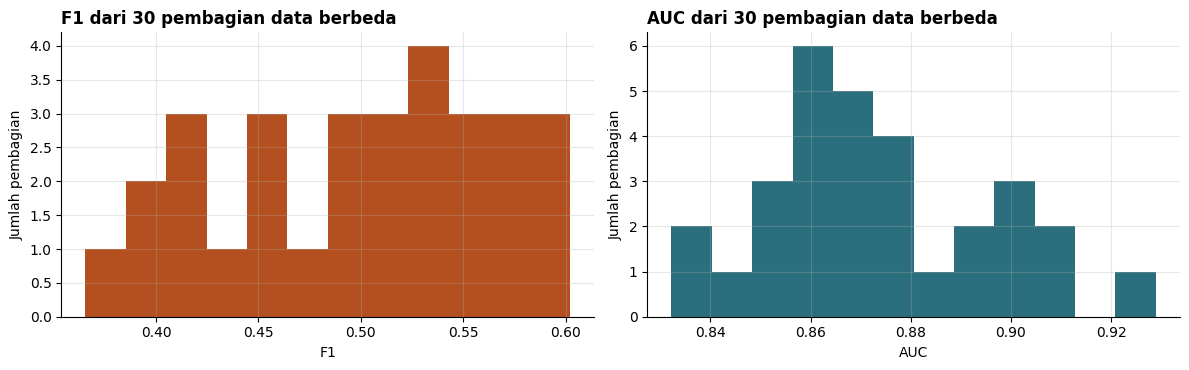

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, kolom, warna in [(axes[0], "F1", WARNA_SOROT), (axes[1], "AUC", WARNA)]:
    ax.hist(hasil_split[kolom], bins=12, color=warna)
    ax.set_title(f"{kolom} dari 30 pembagian data berbeda", loc="left", fontweight="bold")
    ax.set_xlabel(kolom)
    ax.set_ylabel("Jumlah pembagian")
plt.tight_layout()
plt.show()

💬 **Amati:** model yang sama, data yang sama, hanya cara membaginya yang berbeda. Berapa F1 terendah dan tertinggi? Jika temanmu memakai `random_state` lain lalu melaporkan F1 0,60 sementara kamu 0,40, siapa yang modelnya lebih baik?

> **Masalahnya:** satu data uji hanya berisi ±62 responden. Sedikit perbedaan pelanggan yang masuk ke data uji sudah cukup menggeser angka. Kita butuh cara menilai yang **lebih stabil**.

---
## 4. K-fold cross-validation

### 4.1 Idenya

**Data latih** dibagi menjadi **k bagian** (*fold*). Model dilatih k kali; setiap kali, satu fold dipakai untuk menilai dan sisanya untuk belajar. Hasil akhirnya **rata-rata** dari k nilai, beserta **simpangan bakunya**.

**Data uji tidak disentuh sama sekali.** Ia tetap disimpan untuk penilaian terakhir.

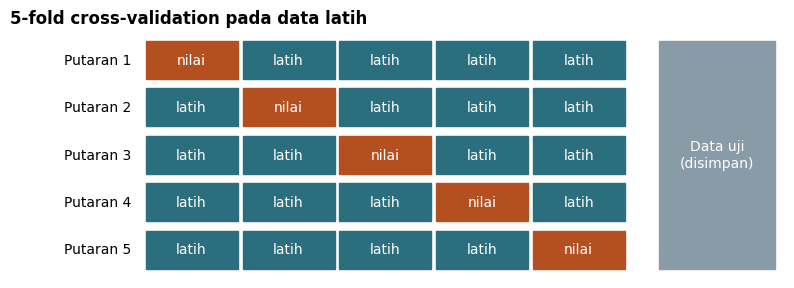

In [6]:
k = 5
fig, ax = plt.subplots(figsize=(10, 3.2))
for putaran in range(k):
    for fold in range(k):
        warna = WARNA_SOROT if fold == putaran else WARNA
        ax.add_patch(plt.Rectangle((fold, k - 1 - putaran), 0.95, 0.8, color=warna))
        ax.text(fold + 0.47, k - 1 - putaran + 0.4, "nilai" if fold == putaran else "latih",
                ha="center", va="center", color="white", fontsize=10)
    ax.text(-0.15, k - 1 - putaran + 0.4, f"Putaran {putaran + 1}", ha="right", va="center")
ax.add_patch(plt.Rectangle((k + 0.3, 0), 1.2, k - 0.2, color=WARNA_ABU))
ax.text(k + 0.9, (k - 0.2) / 2, "Data uji\n(disimpan)", ha="center", va="center", color="white", fontsize=10)
ax.set_xlim(-1.4, k + 1.6)
ax.set_ylim(-0.2, k)
ax.axis("off")
ax.set_title("5-fold cross-validation pada data latih", loc="left", fontweight="bold")
plt.show()

### 4.2 `cross_val_score` dengan pipeline

`StratifiedKFold` menjaga persentase responden sama di setiap fold, seperti `stratify` di `train_test_split`.

Kenapa pipeline penting di sini? Di **setiap putaran**, scaler dan imputer harus di-*fit* hanya pada fold latih, bukan pada fold penilai. Pipeline melakukannya otomatis. Tanpa pipeline, kebocoran data bentuk 2 dari Pertemuan 3 terjadi lima kali.

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

skor_auc = cross_val_score(buat_logreg(), X_train, y_train, cv=cv, scoring="roc_auc")
print("AUC per fold:", skor_auc.round(3))
print(f"Rata-rata   : {skor_auc.mean():.3f} ± {skor_auc.std():.3f}")

AUC per fold: [0.873 0.859 0.85  0.881 0.867]
Rata-rata   : 0.866 ± 0.011


### 4.3 Membandingkan model dengan beberapa ukuran sekaligus

`cross_validate` menghitung beberapa ukuran dalam satu kali jalan.

In [8]:
from sklearn.model_selection import cross_validate

kandidat = {
    "Logistic Regression": buat_logreg(),
    'LogReg "balanced"': buat_logreg(class_weight="balanced"),
    "Decision Tree (depth 3)": Pipeline([("persiapan", buat_persiapan(FITUR_ANGKA, scaling=False)),
                                         ("model", DecisionTreeClassifier(max_depth=3, random_state=42))]),
    "Random Forest": Pipeline([("persiapan", buat_persiapan(FITUR_ANGKA, scaling=False)),
                               ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))]),
}

baris = []
for nama, model in kandidat.items():
    hasil = cross_validate(model, X_train, y_train, cv=cv, scoring=["roc_auc", "f1", "precision", "recall"])
    baris.append({"model": nama,
                  **{f"{u}_rata2": hasil[f"test_{u}"].mean() for u in ["roc_auc", "f1", "precision", "recall"]},
                  "roc_auc_sd": hasil["test_roc_auc"].std()})
tabel_cv = pd.DataFrame(baris).set_index("model").round(3)
tabel_cv

,roc_auc_rata2,f1_rata2,precision_rata2,recall_rata2,roc_auc_sd
model,,,,,
Logistic Regression,0.866,0.505,0.719,0.391,0.011
"LogReg ""balanced""",0.866,0.522,0.398,0.758,0.011
Decision Tree (depth 3),0.750,0.352,0.596,0.258,0.031
Random Forest,0.848,0.450,0.686,0.339,0.019


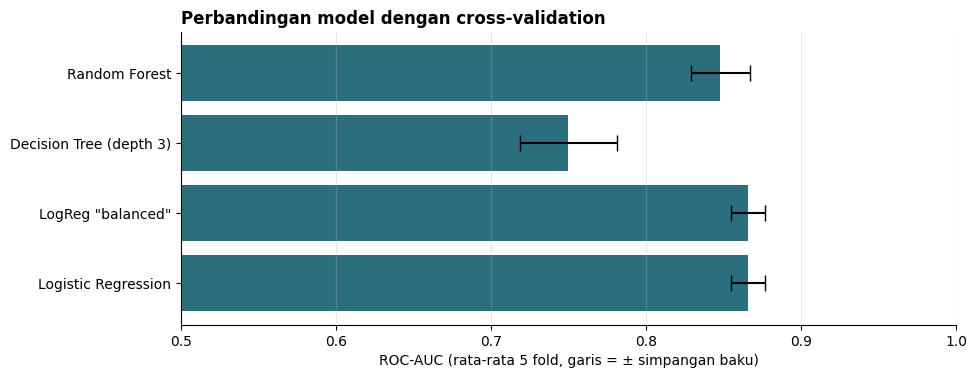

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
posisi = np.arange(len(tabel_cv))
ax.barh(posisi, tabel_cv["roc_auc_rata2"], xerr=tabel_cv["roc_auc_sd"], color=WARNA, capsize=6)
ax.set_yticks(posisi)
ax.set_yticklabels(tabel_cv.index)
ax.set_xlim(0.5, 1)
ax.set_xlabel("ROC-AUC (rata-rata 5 fold, garis = ± simpangan baku)")
ax.set_title("Perbandingan model dengan cross-validation", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
plt.show()

💬 **Diskusi:**

1. Logistic Regression biasa dan "balanced" punya AUC yang sama. Kenapa? (Petunjuk: `class_weight` menggeser keputusan 0/1, tetapi urutan peluangnya hampir tidak berubah.)
2. Simpangan baku mana yang terbesar? Apa artinya bagi kepercayaan kita pada model itu?

---
## 5. Tuning: mencari pengaturan terbaik

### 5.1 Parameter vs hyperparameter

| | Parameter | Hyperparameter |
|---|---|---|
| Siapa yang menentukan | **Dipelajari** model saat `fit` | **Ditentukan kita** sebelum `fit` |
| Contoh | Koefisien Logistic Regression, aturan pohon | `max_depth`, `min_samples_leaf`, `C`, `n_estimators` |
| Cara memilih | Otomatis | Dicoba-coba dengan **cross-validation** |

### 5.2 Kurva validasi: kedalaman pohon, versi yang benar

Di Pertemuan 5 kita melihat overfitting dengan membandingkan skor latih dan skor **uji**. Itu berbahaya jika dipakai untuk **memilih**: lama-lama data uji ikut "dihafal". Cara yang benar: pakai skor **cross-validation**.

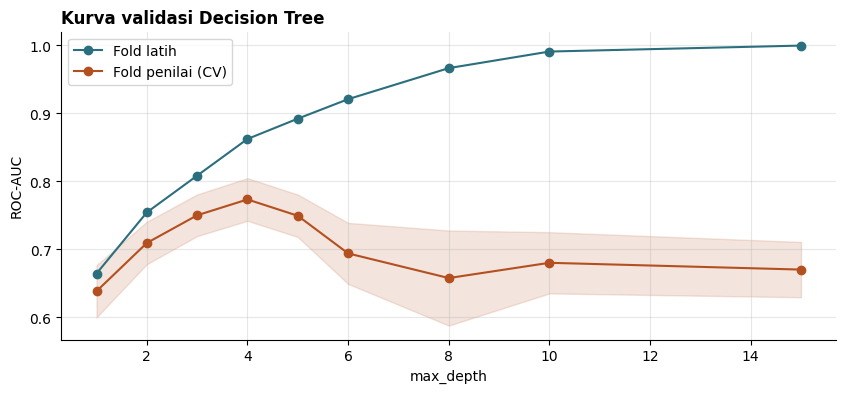

In [10]:
from sklearn.model_selection import validation_curve

pohon = Pipeline([("persiapan", buat_persiapan(FITUR_ANGKA, scaling=False)),
                  ("model", DecisionTreeClassifier(random_state=42))])
daftar_kedalaman = [1, 2, 3, 4, 5, 6, 8, 10, 15]

skor_latih, skor_cv = validation_curve(pohon, X_train, y_train, param_name="model__max_depth",
                                       param_range=daftar_kedalaman, cv=cv, scoring="roc_auc")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daftar_kedalaman, skor_latih.mean(axis=1), marker="o", color=WARNA, label="Fold latih")
ax.plot(daftar_kedalaman, skor_cv.mean(axis=1), marker="o", color=WARNA_SOROT, label="Fold penilai (CV)")
ax.fill_between(daftar_kedalaman, skor_cv.mean(axis=1) - skor_cv.std(axis=1),
                skor_cv.mean(axis=1) + skor_cv.std(axis=1), color=WARNA_SOROT, alpha=0.15)
ax.set_title("Kurva validasi Decision Tree", loc="left", fontweight="bold")
ax.set_xlabel("max_depth")
ax.set_ylabel("ROC-AUC")
ax.legend()
plt.show()

💬 **Amati:** di kedalaman berapa skor CV paling tinggi? Apa yang terjadi setelahnya? Pita oranye menunjukkan ± simpangan baku antar fold.

### 5.3 `GridSearchCV`: mencoba semua kombinasi

`GridSearchCV` mencoba setiap kombinasi hyperparameter dengan cross-validation, lalu memilih yang terbaik. Nama hyperparameter di dalam pipeline ditulis `namaLangkah__namaParameter`.

In [11]:
from sklearn.model_selection import GridSearchCV

grid_pohon = GridSearchCV(
    pohon,
    param_grid={"model__max_depth": [2, 3, 4, 5, 6, 8, None],
                "model__min_samples_leaf": [1, 5, 20]},
    cv=cv, scoring="roc_auc",
)
grid_pohon.fit(X_train, y_train)

print("Kombinasi dicoba :", len(grid_pohon.cv_results_["params"]), "× 5 fold =",
      len(grid_pohon.cv_results_["params"]) * 5, "kali melatih")
print("Terbaik          :", grid_pohon.best_params_)
print(f"AUC CV terbaik   : {grid_pohon.best_score_:.3f}")

Kombinasi dicoba : 21 × 5 fold = 105 kali melatih
Terbaik          : {'model__max_depth': 6, 'model__min_samples_leaf': 20}
AUC CV terbaik   : 0.806


In [12]:
hasil_grid = pd.DataFrame(grid_pohon.cv_results_)
hasil_grid["max_depth"] = [str(p["model__max_depth"]) for p in hasil_grid["params"]]
hasil_grid["min_samples_leaf"] = [p["model__min_samples_leaf"] for p in hasil_grid["params"]]
tabel_grid = hasil_grid.pivot(index="max_depth", columns="min_samples_leaf", values="mean_test_score")
tabel_grid = tabel_grid.loc[["2", "3", "4", "5", "6", "8", "None"]]
tabel_grid.round(3)

min_samples_leaf,1,5,20
max_depth,,,
2,0.709,0.709,0.710
3,0.750,0.757,0.760
4,0.773,0.786,0.797
5,0.749,0.777,0.800
6,0.694,0.742,0.806
8,0.658,0.736,0.797
None,0.661,0.726,0.798


💬 **Amati:** pohon tanpa batas kedalaman (`None`) dengan `min_samples_leaf=1` jelas overfitting. Bagaimana jika `min_samples_leaf` dinaikkan? Dua hyperparameter bisa saling "menolong".

### 5.4 Tuning Logistic Regression dan Random Forest

In [13]:
grid_logreg = GridSearchCV(buat_logreg(), param_grid={"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
                           cv=cv, scoring="roc_auc").fit(X_train, y_train)

grid_hutan = GridSearchCV(
    Pipeline([("persiapan", buat_persiapan(FITUR_ANGKA, scaling=False)),
              ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))]),
    param_grid={"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 5, 10]},
    cv=cv, scoring="roc_auc",
).fit(X_train, y_train)

ringkas_tuning = pd.DataFrame([
    {"model": "Decision Tree", "terbaik": grid_pohon.best_params_, "AUC_CV": grid_pohon.best_score_},
    {"model": "Logistic Regression", "terbaik": grid_logreg.best_params_, "AUC_CV": grid_logreg.best_score_},
    {"model": "Random Forest", "terbaik": grid_hutan.best_params_, "AUC_CV": grid_hutan.best_score_},
]).set_index("model")
ringkas_tuning.round(3)

,terbaik,AUC_CV
model,,
Decision Tree,"{'model__max_depth': 6, 'model__min_samples_le...",0.806
Logistic Regression,{'model__C': 0.1},0.867
Random Forest,"{'model__max_depth': 8, 'model__min_samples_le...",0.859


💬 **Diskusi:** bandingkan AUC CV Logistic Regression setelah tuning dengan tabel bagian 4.3 (C = 1, bawaan). Berapa kenaikannya? Tuning bukan sihir: sering kali pilihan **fitur** dan **model** lebih berpengaruh daripada mengutak-atik hyperparameter.

### 5.5 Penilaian terakhir di data uji: sekali saja

Model dipilih **hanya** dengan skor CV. Setelah semua keputusan diambil, barulah data uji dipakai **satu kali**.

In [14]:
for nama, grid in [("Decision Tree", grid_pohon), ("Logistic Regression", grid_logreg), ("Random Forest", grid_hutan)]:
    auc_uji = roc_auc_score(y_test, grid.predict_proba(X_test)[:, 1])
    print(f"{nama:20s} AUC CV {grid.best_score_:.3f} | AUC uji {auc_uji:.3f}")

Decision Tree        AUC CV 0.806 | AUC uji 0.810
Logistic Regression  AUC CV 0.867 | AUC uji 0.875
Random Forest        AUC CV 0.859 | AUC uji 0.848


💬 **Amati:** apakah AUC uji dekat dengan AUC CV? Jika dekat, berarti CV memberi perkiraan yang jujur tentang kinerja di data baru.

Kita memilih **Logistic Regression hasil tuning** sebagai model kampanye: AUC CV tertinggi, stabil, dan mudah dijelaskan.

---
## 6. Batas peluang yang paling menguntungkan

### 6.1 Menghitung untung

Untuk setiap pelanggan yang dikirimi katalog:

- Jika merespons (TP): untung **11 − 3 = 8**
- Jika tidak merespons (FP): rugi **3**
- Yang tidak dikirimi (TN, FN): tidak ada biaya, tidak ada untung

`untung = 11 × TP − 3 × (TP + FP)`

**Titik impas:** katalog menguntungkan jika precision ≥ 3/11 ≈ **27%**. Batas 0,5 dari Pertemuan 5 menghasilkan precision ±67%: aman, tetapi mungkin terlalu hati-hati.

In [15]:
def hitung_untung(y_benar, peluang, batas, biaya=BIAYA_KONTAK, untung=UNTUNG_RESPONS):
    dikirim = peluang >= batas
    tp = int((dikirim & (np.asarray(y_benar) == 1)).sum())
    n_kirim = int(dikirim.sum())
    return {"batas": batas, "dikirim": n_kirim, "responden": tp, "untung": untung * tp - biaya * n_kirim}

print(f"Titik impas precision: {BIAYA_KONTAK / UNTUNG_RESPONS:.1%}")

Titik impas precision: 27.3%


### 6.2 Memilih batas di data latih, dengan cross-validation

Batas juga sebuah "pengaturan", jadi **tidak boleh dipilih dengan data uji**. Kita pakai `cross_val_predict`: setiap pelanggan latih mendapat peluang dari model yang **tidak pernah melihat** pelanggan itu.

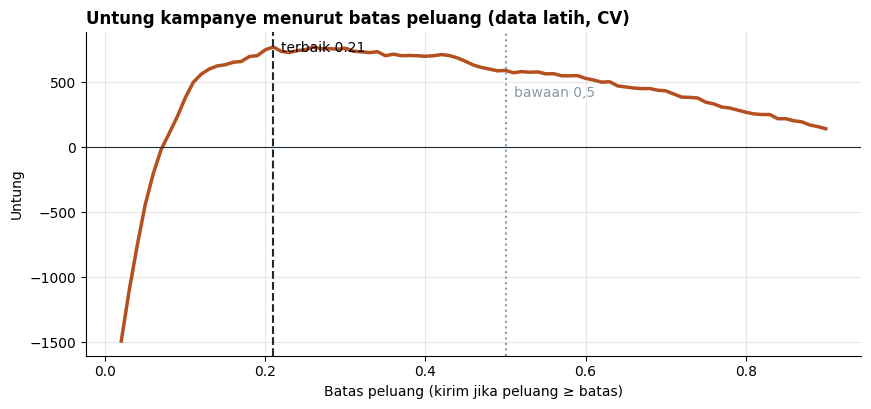

Batas paling menguntungkan: 0.21


In [16]:
from sklearn.model_selection import cross_val_predict

model_kampanye = grid_logreg.best_estimator_
peluang_cv = cross_val_predict(model_kampanye, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

daftar_batas = np.round(np.arange(0.02, 0.91, 0.01), 2)
kurva_untung = pd.DataFrame([hitung_untung(y_train, peluang_cv, b) for b in daftar_batas])
BATAS_TERBAIK = float(kurva_untung.loc[kurva_untung["untung"].idxmax(), "batas"])

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(kurva_untung["batas"], kurva_untung["untung"], color=WARNA_SOROT, linewidth=2.5)
ax.axvline(BATAS_TERBAIK, color="#1B2A35", linestyle="--")
ax.axvline(0.5, color=WARNA_ABU, linestyle=":")
ax.text(BATAS_TERBAIK + 0.01, kurva_untung["untung"].max() * 0.95, f"terbaik {BATAS_TERBAIK:.2f}")
ax.text(0.51, kurva_untung["untung"].max() * 0.5, "bawaan 0,5", color=WARNA_ABU)
ax.axhline(0, color="#1B2A35", linewidth=0.8)
ax.set_title("Untung kampanye menurut batas peluang (data latih, CV)", loc="left", fontweight="bold")
ax.set_xlabel("Batas peluang (kirim jika peluang ≥ batas)")
ax.set_ylabel("Untung")
plt.show()

print("Batas paling menguntungkan:", BATAS_TERBAIK)

💬 **Amati:** bentuk kurvanya seperti bukit. Kenapa untung turun jika batas **terlalu rendah**? Dan jika batas **terlalu tinggi**?

### 6.3 Membandingkan strategi di data uji

In [17]:
model_kampanye.fit(X_train, y_train)
peluang_uji = model_kampanye.predict_proba(X_test)[:, 1]

strategi = pd.DataFrame([
    {"strategi": "Tidak mengirim sama sekali", **hitung_untung(y_test, peluang_uji, 1.01)},
    {"strategi": "Kirim ke semua pelanggan", **hitung_untung(y_test, peluang_uji, 0.0)},
    {"strategi": "Model, batas 0,5", **hitung_untung(y_test, peluang_uji, 0.5)},
    {"strategi": f"Model, batas {BATAS_TERBAIK:.2f}", **hitung_untung(y_test, peluang_uji, BATAS_TERBAIK)},
]).set_index("strategi")
strategi["precision"] = (strategi["responden"] / strategi["dikirim"]).round(3)
strategi

,batas,dikirim,responden,untung,precision
strategi,,,,,
Tidak mengirim sama sekali,1.01,0,0,0,NaN
Kirim ke semua pelanggan,0.00,406,62,-536,0.153
"Model, batas 0,5",0.50,32,22,146,0.688
"Model, batas 0.21",0.21,94,43,191,0.457


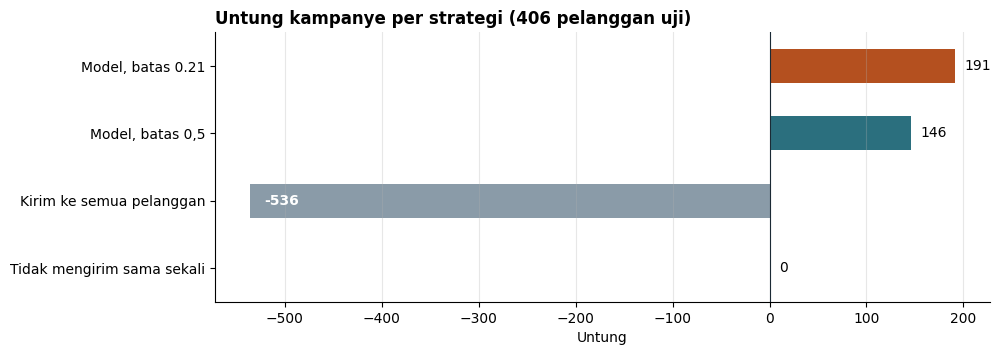

In [18]:
warna_bar = [WARNA_ABU, WARNA_ABU, WARNA, WARNA_SOROT]
ax = strategi["untung"].plot(kind="barh", color=warna_bar, figsize=(10, 3.5))
ax.axvline(0, color="#1B2A35", linewidth=0.8)
for i, v in enumerate(strategi["untung"]):
    if v >= 0:
        ax.text(v + 10, i, f"{v:,}", va="center", ha="left")
    else:
        ax.text(v + 15, i, f"{v:,}", va="center", ha="left", color="white", fontweight="bold")
ax.set_title(f"Untung kampanye per strategi ({len(y_test)} pelanggan uji)", loc="left", fontweight="bold")
ax.set_xlabel("Untung")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
plt.show()

💬 **Diskusi:**

1. Kenapa "kirim ke semua" justru **rugi**?
2. Batas terbaik mengirim lebih banyak katalog daripada batas 0,5. Precision-nya turun, tetapi untungnya naik. Bagaimana itu mungkin?
3. Batas terbaik dipilih di data latih (CV), lalu diuji di data uji. Kenapa ini lebih jujur daripada mencari batas langsung di data uji?

---
## 7. Simulasi skenario: bagaimana jika angkanya berubah?

Biaya cetak bisa naik, atau tim marketing menambah hadiah sehingga keuntungan per respons naik. Batas terbaik ikut berubah.

In [19]:
def simulasi(biaya, untung):
    kurva = pd.DataFrame([hitung_untung(y_train, peluang_cv, b, biaya, untung) for b in daftar_batas])
    batas = float(kurva.loc[kurva["untung"].idxmax(), "batas"])
    uji = hitung_untung(y_test, peluang_uji, batas, biaya, untung)
    semua = hitung_untung(y_test, peluang_uji, 0.0, biaya, untung)
    return {"biaya": biaya, "untung_per_respons": untung, "titik_impas_precision": round(biaya / untung, 3),
            "batas_terbaik": batas, "dikirim_uji": uji["dikirim"], "untung_uji": uji["untung"],
            "untung_jika_kirim_semua": semua["untung"]}

skenario = pd.DataFrame([simulasi(b, u) for b, u in [(3, 11), (1, 11), (6, 11), (3, 20), (3, 6)]])
skenario

,biaya,untung_per_respons,titik_impas_precision,batas_terbaik,dikirim_uji,untung_uji,untung_jika_kirim_semua
0,3,11,0.273,0.21,94,191,-536
1,1,11,0.091,0.11,152,431,276
2,6,11,0.545,0.59,25,59,-1754
3,3,20,0.150,0.12,149,613,22
4,3,6,0.500,0.42,42,36,-846


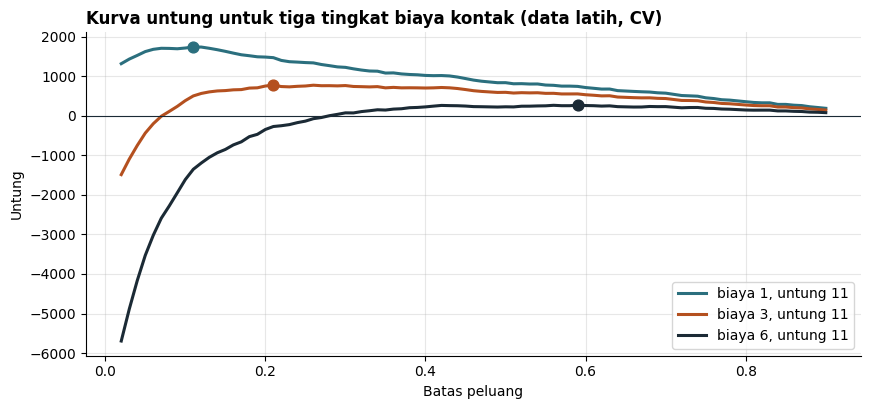

In [20]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for (b, u), warna in zip([(1, 11), (3, 11), (6, 11)], [WARNA, WARNA_SOROT, "#1B2A35"]):
    kurva = pd.DataFrame([hitung_untung(y_train, peluang_cv, t, b, u) for t in daftar_batas])
    ax.plot(kurva["batas"], kurva["untung"], color=warna, linewidth=2.2, label=f"biaya {b}, untung {u}")
    terbaik = kurva.loc[kurva["untung"].idxmax()]
    ax.scatter(terbaik["batas"], terbaik["untung"], color=warna, zorder=3, s=60)
ax.axhline(0, color="#1B2A35", linewidth=0.8)
ax.set_title("Kurva untung untuk tiga tingkat biaya kontak (data latih, CV)", loc="left", fontweight="bold")
ax.set_xlabel("Batas peluang")
ax.set_ylabel("Untung")
ax.legend()
plt.show()

💬 **Diskusi:** jika biaya kontak naik dua kali lipat, batas terbaik naik atau turun? Kenapa? Jika tim marketing bisa menaikkan keuntungan per respons, apa yang terjadi pada jumlah katalog yang sebaiknya dikirim?

> **Coba sendiri:** ubah angka di `simulasi(biaya, untung)` dengan skenario yang menurutmu realistis.

---
## 8. Model final dan daftar kirim kampanye ke-7

Setelah model, hyperparameter, dan batas dipilih, kita latih ulang model dengan **seluruh** data (latih + uji) agar belajar dari sebanyak mungkin pelanggan. Data uji sudah selesai tugasnya.

In [21]:
import joblib

model_final = grid_logreg.best_estimator_
model_final.fit(X, y)

paket_model = {"model": model_final, "batas": BATAS_TERBAIK, "fitur": FITUR_ANGKA + FITUR_KATEGORI,
               "biaya_kontak": BIAYA_KONTAK, "untung_respons": UNTUNG_RESPONS}
FILE_MODEL = "model_kampanye7.joblib"
joblib.dump(paket_model, FOLDER + FILE_MODEL)
print("Tersimpan:", FILE_MODEL)

Tersimpan: model_kampanye7.joblib


In [22]:
# Memakai model untuk membuat daftar kirim
paket = joblib.load(FOLDER + FILE_MODEL)

daftar = df[["ID", "NamaSegmen"]].copy()
daftar["peluang"] = paket["model"].predict_proba(df[paket["fitur"]])[:, 1].round(3)
daftar["kirim_katalog"] = (daftar["peluang"] >= paket["batas"]).astype(int)
daftar = daftar.sort_values("peluang", ascending=False)

print(f"Dikirimi katalog: {daftar['kirim_katalog'].sum()} dari {len(daftar)} pelanggan")
daftar.groupby("NamaSegmen")["kirim_katalog"].agg(["sum", "mean"]).rename(
    columns={"sum": "dikirim", "mean": "porsi_dikirim"}).round(2)

Dikirimi katalog: 459 dari 2026 pelanggan


,dikirim,porsi_dikirim
NamaSegmen,,
Hemat,84,0.10
Keluarga Mapan,141,0.26
Pemburu Diskon,53,0.26
Premium,181,0.39


In [23]:
FILE_DAFTAR = "daftar_kirim_kampanye7.csv"
daftar.to_csv(FOLDER + FILE_DAFTAR, index=False)
print("Tersimpan:", FILE_DAFTAR)
daftar.head(10)

Tersimpan: daftar_kirim_kampanye7.csv


,ID,NamaSegmen,peluang,kirim_katalog
407,3725,Premium,0.997,1
237,10089,Premium,0.986,1
1795,3009,Premium,0.984,1
941,8545,Premium,0.976,1
317,7381,Premium,0.974,1
1692,7872,Premium,0.973,1
1759,3138,Premium,0.966,1
1967,3520,Premium,0.960,1
1260,2535,Keluarga Mapan,0.954,1
395,5067,Premium,0.952,1


💬 **Amati:** segmen mana yang paling banyak dikirimi katalog? Cocokkah dengan temuan Pertemuan 4?

> **Catatan:** di cerita ini kita memakai data kampanye **sebelumnya** untuk memilih penerima kampanye **berikutnya**. Dalam praktik, hasil kampanye ke-7 nanti perlu dicatat dan dipakai untuk memperbarui model.

---
## 9. Cross-validation untuk regresi

Prinsip yang sama berlaku untuk model regresi `TotalSpend` dari Pertemuan 5. Bedanya: pakai `KFold` (tanpa stratifikasi), dan ukuran "error" ditulis negatif karena scikit-learn selalu memaksimalkan skor.

In [24]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

FITUR_PROFIL = ["Income", "Age", "Children", "Tenure_days"]
X_reg = df[FITUR_PROFIL + FITUR_KATEGORI]
y_reg = df["TotalSpend"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)
for nama, m in [("Linear Regression", Pipeline([("persiapan", buat_persiapan(FITUR_PROFIL)), ("model", LinearRegression())])),
                ("Random Forest", Pipeline([("persiapan", buat_persiapan(FITUR_PROFIL, scaling=False)),
                                            ("model", RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                                                            random_state=42, n_jobs=-1))]))]:
    mae = -cross_val_score(m, Xr_train, yr_train, cv=cv_reg, scoring="neg_mean_absolute_error")
    print(f"{nama:18s} MAE per fold {mae.round(0)} → {mae.mean():.0f} ± {mae.std():.0f}")

Linear Regression  MAE per fold [232. 232. 242. 246. 243.] → 239 ± 6
Random Forest      MAE per fold [180. 175. 203. 218. 180.] → 191 ± 17


💬 **Amati:** apakah urutan model sama dengan Pertemuan 6 (MAE uji Linear 237, Random Forest 186)? Fold mana yang paling sulit ditebak?

---
## 10. Latihan mandiri

**Latihan 1 — Berapa fold?** Ulangi bagian 4.2 dengan `n_splits` = 3, 5, dan 10. Bagaimana rata-rata dan simpangan baku AUC berubah? Apa untung-ruginya memakai fold lebih banyak?

In [25]:
# Tulis jawaban Latihan 1 di sini

**Latihan 2 — Ukuran pemilih.** Jalankan ulang `GridSearchCV` untuk Decision Tree dengan `scoring="f1"` dan `scoring="recall"`. Apakah hyperparameter terbaiknya sama dengan `scoring="roc_auc"`? Kenapa bisa berbeda?

In [26]:
# Tulis jawaban Latihan 2 di sini

**Latihan 3 — Random Forest untuk kampanye.** Ulangi bagian 6 dengan `grid_hutan.best_estimator_`. Batas terbaik berapa, dan berapa untungnya di data uji dibanding Logistic Regression?

In [27]:
# Tulis jawaban Latihan 3 di sini

**Latihan 4 — Memilih batas dengan curang.** Cari batas paling menguntungkan **langsung di data uji** (pakai `peluang_uji`). Bandingkan dengan `BATAS_TERBAIK`. Untung mana yang lebih besar? Kenapa angka itu terlalu optimistis untuk dilaporkan ke direksi?

In [28]:
# Tulis jawaban Latihan 4 di sini

**Latihan 5 (tantangan) — Kebocoran di dalam CV.** Lakukan scaling pada **seluruh** `X_train` dulu (di luar pipeline), baru jalankan `cross_val_score` dengan `LogisticRegression` saja. Bandingkan AUC-nya dengan bagian 4.2. Walaupun bedanya kecil, jelaskan kenapa cara ini salah.

In [29]:
# Tulis jawaban Latihan 5 di sini

---
## 11. Tugas: rekomendasi akhir kampanye ke-7

Tulis **memo 5–7 kalimat** untuk direksi RetailKu yang menjawab:

1. Model apa yang dipakai, dan kenapa kamu yakin hasilnya bukan kebetulan (sebutkan hasil cross-validation)?
2. Berapa pelanggan yang dikirimi katalog, dan berapa perkiraan untungnya dibanding mengirim ke semua pelanggan?
3. Jika biaya cetak naik menjadi 6, apa yang harus diubah?
4. Satu risiko atau keterbatasan dari rekomendasimu.

Lampirkan `daftar_kirim_kampanye7.csv`.

---
## Rangkuman

| Konsep | Inti | Alat |
|---|---|---|
| Satu split bisa menipu | Hasil berubah-ubah tergantung pelanggan yang masuk data uji | Ulangi `train_test_split` dengan seed berbeda |
| Cross-validation | Rata-rata dan simpangan baku dari k fold; data uji tidak disentuh | `StratifiedKFold`, `cross_val_score`, `cross_validate` |
| Pipeline di dalam CV | Persiapan di-fit ulang di setiap fold, tanpa kebocoran | `Pipeline` |
| Hyperparameter | Ditentukan kita, dipilih dengan CV | `validation_curve`, `GridSearchCV` |
| Data uji | Dipakai sekali, di akhir | `best_estimator_` → skor uji |
| Batas berbasis untung | `untung = 11 × TP − 3 × dikirim`; titik impas precision 27% | `cross_val_predict`, kurva untung |
| Simulasi skenario | Biaya dan keuntungan berubah → batas berubah | Fungsi `simulasi()` |
| Model final | Latih ulang dengan semua data, simpan bersama batasnya | `joblib.dump`, `joblib.load` |

**Selanjutnya:** terapkan semua yang sudah dipelajari dari Pertemuan 1–7 di **final project**.